# Neural network from scratch in NumPy

A learning project: a multilayer perceptron with manual backpropagation, Adam and early stopping.
Experiments cover synthetic data, MNIST-1D and MNIST digits.

Run the cells in order. The MNIST-1D search trains 30 models; the MNIST experiment uses the full dataset.
Data is cached in `data/` beside the notebook when run from its directory.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

## 1. MLP implementation

Hidden layers use ReLU; the output is converted to softmax probabilities.
The original implementation is retained with small fixes to the loss, early stopping and confusion matrix.
Only softmax cross-entropy classification is supported. The method named `Xavier_Glorot_init` uses a custom scale of
`sqrt(4 / (fan_in + fan_out))`.

In [2]:
class MLP():

    def __init__(self,X,y, dimensions):
        self.X=np.array(X)
        self.y=np.array(y)
        self.ofsets,self.weights=self.Xavier_Glorot_init(dimensions)
        self.N=len(dimensions)

    def Xavier_Glorot_init(self,dimensions):
        weights=[None]*(len(dimensions))
        biases=[None]*len(dimensions)
        for idx,i in enumerate(dimensions):
            biases[idx]= np.zeros(shape=(1,i))
            if idx!=0:
                dh=dimensions[idx-1]
            else:
                dh=self.X.shape[1]
            dh_prim=i
            weights[idx]=np.random.normal(size=(dh,dh_prim),scale=np.sqrt(4/(dh+dh_prim)),loc=0)
        return biases,weights
    
    def forward_pass(self, X_param):
        h_list=[None]*self.N
        f_list=[None]*self.N
        h_list[0]=X_param
        f_list[0]=self.f_func(0,h_list[0])
                
        for i in range(1,self.N):
            h_list[i]=self.ReLU(f_list[i-1])
            f_list[i]=self.f_func(i,h_list[i])
        return f_list,h_list

    def indicator(self,func):
        return np.where(func>0,1,0)

    def f_func(self,i,h):
        return self.ofsets[i]+h@self.weights[i]

    def ReLU(self,func):
        return np.maximum(func,0)

    def softmax(self,out):
        max_val=np.max(out,keepdims=True, axis=1)
        scaled_out=out-max_val
        return np.exp(scaled_out)/(np.sum(np.exp(scaled_out),axis=1,keepdims=True))

    def cross_entropy_loss(self, func, y):
        shifted = func - np.max(func, axis=1, keepdims=True)
        log_probs = shifted - np.log(np.sum(np.exp(shifted), axis=1, keepdims=True))
        return -np.mean(np.sum(y * log_probs, axis=1))

    def first_deriv(self,val,y,entropy=True, multiclass=True):
        if entropy and multiclass:
            return self.softmax(val)-y
        raise NotImplementedError("Only softmax cross-entropy classification is supported.")
        
    def backward(self,X,y,entropy=True,multiclass=True):
        dl_dw_list=[None]*self.N
        dl_do_list=[None]*self.N
        dl_df_list=[None]*self.N
        all_f,all_h=self.forward_pass(X)
        dl_df_list[self.N-1]=self.first_deriv(all_f[-1],y,entropy,multiclass)/X.shape[0]
        for i in range(self.N-1,-1,-1):
            dl_df=np.array(dl_df_list[i])
            
            dl_do_list[i] = np.sum(dl_df, axis=0, keepdims=True)
            dl_dw_list[i]=all_h[i].T@dl_df
            if i>0:
                dl_df_list[i-1]=self.indicator(all_f[i-1])*(dl_df@self.weights[i].T)
        return dl_dw_list, dl_do_list
    
    def divide_data(self,training_size): 
        idx=np.array([i for i in range(training_size)])
        np.random.shuffle(idx)
        return idx

    def change_input_y_to_output(self,y):
         return(np.argmax(y,axis=1))
    

    def Adam_param(self,m_w,v_w,m_o,v_o,dl_dw,dl_do,beta,gamma,t):
        m_w=(beta*m_w+(1-beta)*dl_dw)
        m_h = m_w / (1 - beta**(t+1))
        v_w=(gamma*v_w+(1-gamma)*(dl_dw**2))
        v_h = v_w / (1 - gamma**(t+1)) 
        m_o=(beta*m_o+(1-beta)*dl_do)
        m_h_o = m_o / (1 - beta**(t+1))
        v_o=(gamma*v_o+(1-gamma)*(dl_do**2))
        v_hat_o = v_o / (1 - gamma**(t+1))
        return m_w,m_h,v_w,v_h,m_o,m_h_o,v_o,v_hat_o

    def Adam_updated(self,lerning_rate,m_hat_w,v_hat_w,m_hat_o,v_hat_o,epsilon):
        w=lerning_rate*(m_hat_w)/(np.sqrt(v_hat_w)+epsilon)
        o=lerning_rate*(m_hat_o)/(np.sqrt(v_hat_o)+epsilon)    
        return w,o                 

    def Predict(slef,X):
        f_list,_=slef.forward_pass(X)
        return np.argmax(f_list[-1],axis=1)

    def evaluate(self,X,y):
        f_list,_=self.forward_pass(X)
        loss = (self.cross_entropy_loss(f_list[-1],y))
        pred=np.argmax(f_list[-1],axis=1)
        true_labels=np.argmax(y,axis=1)
        accuracy=np.mean(pred==true_labels)
        return loss, accuracy

    def visualize(self,train_acc,train_loss,test_loss,test_acc):
        domain=[i for i in range(len(train_acc))]
        fig, ax = plt.subplots(3, 2,figsize=(8,12))
        ax[0,0].plot(domain,train_acc)
        ax[0,0].set_title("Training accuracy by epoch")
        ax[0,1].plot(domain,train_loss)
        ax[0,1].set_title("Training loss by epoch")
        ax[1,0].plot(domain,test_acc)
        ax[1,0].set_title("Accuracy on validation set by epoch")
        ax[1,1].plot(domain,test_loss)
        ax[1,1].set_title("Loss on validation set by epoch")
        ax[2,0].plot(domain,train_acc,color='g', label='Training accuracy')
        ax[2,0].plot(domain,test_acc, color='r', label = 'Validation accuracy')
        ax[2,0].set_title('Training vs Val accuracy')
        ax[2,0].legend()
        ax[2,1].plot(domain,train_loss,color='g', label='Training loss')
        ax[2,1].plot(domain,test_loss, color='r', label = 'Validation loss')
        ax[2,1].set_title('Training vs Val loss')
        ax[2,1].legend()
        plt.show()

    def confussion_matrix(self,y_predict,y):
        size = self.weights[-1].shape[1]
        flat_indices=y* size+y_predict
        conf_mat = np.bincount(flat_indices, minlength=size * size)
        return conf_mat.reshape(size, size)

    
    def vis_conf_matrix(self,arr,fig_size=8,dispaly_numbers=True):
        fig, ax = plt.subplots(figsize=(fig_size, fig_size))
        cax = ax.matshow(arr, cmap="Blues")
        fig.colorbar(cax)
        matrix_size=arr.shape[0]
        if matrix_size<15:
                font_size=12
        elif matrix_size < 30:
                font_size= 8
        else:
                font_size=  6
        if dispaly_numbers:
            for i in range(arr.shape[0]):
                    for j in range(arr.shape[1]):
                            val = arr[i, j]
                            threshold = arr.max() / 2.0
                            color = "white" if val > threshold else "black"
                            if matrix_size < 40:
                                    ax.text(j, i, str(val), va='center', ha='center', color=color, fontsize=font_size, weight='bold')

        ax.set_xlabel('Predicted Labels', fontsize=12)
        ax.set_ylabel('True Labels', fontsize=12)
        ax.xaxis.set_label_position('top') 
        plt.show()
        

    def early_stop_init(self,patience, min_delta,metric='loss'):
        stop_flag=False
        if metric=='loss':
            best_metric=np.inf
        if metric=='acc':
            best_metric=0.0
        self._early_stop_reference = best_metric
        patienc_counter=0
        best_weights=[w.copy() for w in self.weights]
        best_offsets=[o.copy() for o in self.ofsets]
        return stop_flag,best_metric,patienc_counter,best_weights,best_offsets

    def early_stop_step(self,best_metric,best_weights,best_offsets,patienc_counter,min_delta,metric,patience_limit,metric_type='loss'):
        improved = metric < best_metric if metric_type == 'loss' else metric > best_metric
        if improved:
            best_metric = metric
            best_weights = [w.copy() for w in self.weights]
            best_offsets = [o.copy() for o in self.ofsets]
        significant = (metric < self._early_stop_reference - min_delta
                       if metric_type == 'loss' else metric > self._early_stop_reference + min_delta)
        if significant:
            self._early_stop_reference = metric
            patienc_counter = 0
        else:
            patienc_counter += 1
        flag = patienc_counter >= patience_limit
        return flag,best_metric,patienc_counter,best_weights,best_offsets
    def fit(self,X_train,y_train,X_val,y_val,lerning_rate,epoches=100,batch_size=3,beta=0.9, gamma=0.99, epsilon=1e-8, early_stop=True, early_stop_metric='loss',min_delta=.05,patience=10,visualize=True):
        if early_stop_metric not in ('loss', 'acc'):
            raise ValueError("early_stop_metric must be 'loss' or 'acc'.")
        if batch_size < 1 or epoches < 1 or (early_stop and patience < 1):
            raise ValueError("Batch size, epochs and patience must be positive.")
        self.best_epoch_ = None
        self.best_metric_ = None
        t=0
        m_weights=[np.zeros_like(i) for i in self.weights]
        v_weights=[np.zeros_like(i) for i in self.weights]
        m_offsets=[np.zeros_like(i) for i in self.ofsets]
        v_offsets=[np.zeros_like(i) for i in self.ofsets]
        train_loss_list=[]
        train_accuracy_list=[]
        val_loss_list=[]
        val_accuracy_list=[]
        if early_stop:
            stop_flag,best_metric,patienc_counter,best_weights,best_offsets=self.early_stop_init(patience,min_delta,metric=early_stop_metric)
        
        for epoch in range(epoches):
            idx=self.divide_data(len(X_train))    
            for start in range(0,len(X_train),batch_size):
                end = start + batch_size
                X_batch = X_train[idx[start:end]]
                y_batch = y_train[idx[start:end]]
                dl_dw_list, dl_do_list=self.backward(X_batch,y_batch)
                for i in range(len(m_weights)):
                    m_weights[i], m_hat_w, v_weights[i],v_hat_w,m_offsets[i],m_hat_o,v_offsets[i],v_hat_o=self.Adam_param(m_weights[i],v_weights[i],m_offsets[i],v_offsets[i],dl_dw_list[i],dl_do_list[i],beta,gamma,t)
                    w,o=self.Adam_updated(lerning_rate,m_hat_w,v_hat_w,m_hat_o,v_hat_o,epsilon)  
                    self.weights[i]-=w
                    self.ofsets[i]-=o                 
                t+=1
            train_loss,train_acc=self.evaluate(X_train,y_train)
            train_loss_list.append(train_loss)
            train_accuracy_list.append(train_acc)

            val_loss,val_acc=self.evaluate(X_val,y_val)
            val_loss_list.append(val_loss)
            val_accuracy_list.append(val_acc)
            if early_stop:
                 current_metric= val_loss if early_stop_metric=='loss' else val_acc
                 previous_best = best_metric
                 stop_flag,best_metric,patienc_counter,best_weights,best_offsets=self.early_stop_step(best_metric,best_weights,best_offsets,patienc_counter,min_delta,metric=current_metric,patience_limit=patience,metric_type=early_stop_metric)
                 if best_metric != previous_best:
                    self.best_epoch_ = epoch + 1
                 if stop_flag:
                    break     
        
        if visualize:
            self.visualize(train_accuracy_list,train_loss_list,val_loss_list, val_accuracy_list)
        if early_stop:
            self.best_metric_ = best_metric
            self.weights=best_weights
            self.ofsets=best_offsets
            
        

## 2. Train, validation and test splits

Use validation data for model selection and early stopping; keep test data for evaluation.

In [3]:
# Data splits
def train_test_val_split(X,y,training_size=0.8,seed=42): 
        if seed is not None:
                np.random.seed(seed)
        idx=np.array([i for i in range(len(X))])
        np.random.shuffle(idx)
        test = int(training_size * len(idx))
        val= int((test+len(idx))/2)
        idx_train=idx[:test]
        idx_test=idx[test:val]
        idx_val=idx[val:]
        X_train=X[idx_train]
        y_train=y[idx_train]
        X_test=X[idx_test]
        y_test=y[idx_test]
        X_val=X[idx_val]
        y_val=y[idx_val]
        return X_train,y_train, X_test,y_test,X_val,y_val
def train_val_split(X, y, val_ratio=0.2, seed=42):
    if seed is not None:
        np.random.seed(seed)
    indices=np.random.permutation(len(X))
    val_size=int(len(X) * val_ratio)
    
    val_idx=indices[:val_size]
    train_idx= indices[val_size:]
    
    return X[train_idx], y[train_idx], X[val_idx], y[val_idx]

## 3. Synthetic classification data

Three overlapping one-dimensional distributions provide a small initial experiment.

In [4]:
size_1=2000
size_2=2400
size_3=2200
zeros=np.array([0 for i in range(size_1)])
ones=np.array([1 for i in range(size_2)])
twos=np.array([2 for i in range(size_3)])
y=np.eye(3)[np.concat([zeros,ones,twos])]
D_1=np.random.normal(size=(size_1,1),scale=(1),loc=(0))
D_2=np.random.normal(size=(size_2,1),scale=(1),loc=(2))
D_3=np.random.normal(size=(size_3,1),scale=(1),loc=(4))
X=np.vstack([D_1,D_2,D_3])

 

In [5]:
MLP2 = MLP(X, y, dimensions=[8,6,4,3])
X_train,y_train,X_test,y_test,X_val,y_val=train_test_val_split(X,y)

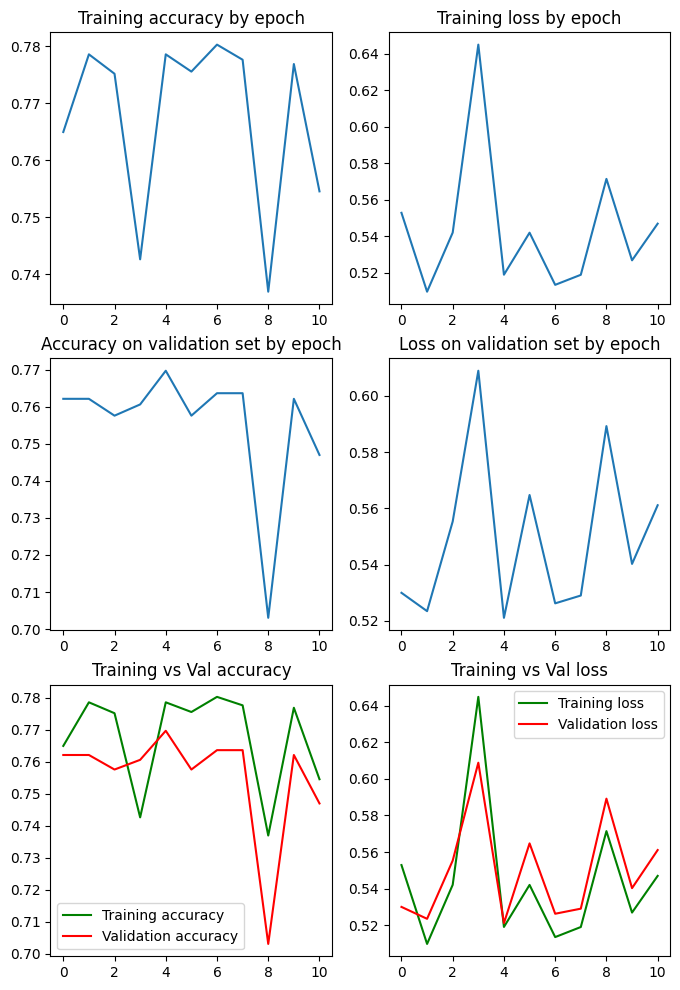

In [6]:
MLP2.fit(X_train,y_train,X_val,y_val,lerning_rate=0.025)

In [7]:
y_pred=MLP2.Predict(X_test)

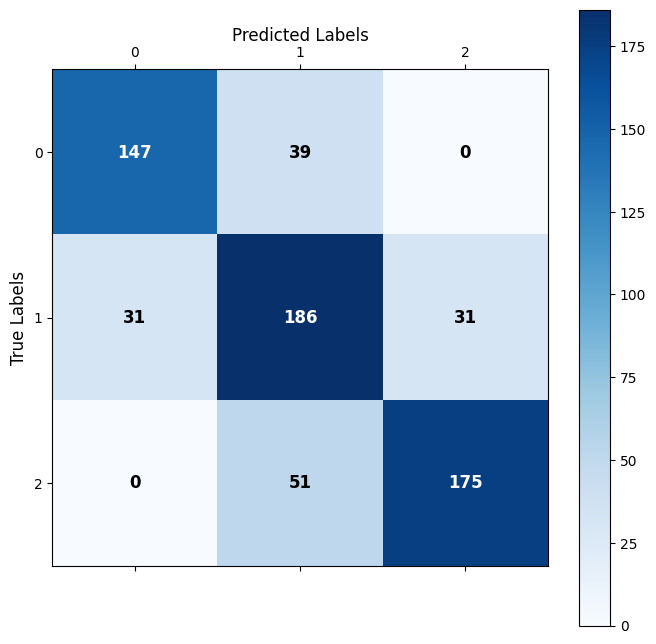

In [8]:
MLP2.vis_conf_matrix(MLP2.confussion_matrix(y_predict=y_pred,y=MLP2.change_input_y_to_output(y_test)))

In [9]:
print(f"Synthetic test accuracy: {np.mean(y_pred == MLP2.change_input_y_to_output(y_test)):.2%}")

Synthetic test accuracy: 76.97%


## 4. MNIST-1D

Select learning rate, layer sizes and batch size using validation accuracy. The test set is evaluated once after selection.

In [10]:
import mnist1d

args=mnist1d.get_dataset_args()
data = mnist1d.get_dataset(args, path=str(DATA_DIR / "mnist1d_data.pkl"), verbose=False)
X_train_full = data['x']
y_train_full = np.eye(10)[data['y']]
X_test = data['x_test']
y_test = np.eye(10)[data['y_test']]
X_train, y_train, X_val, y_val = train_val_split(X_train_full, y_train_full, val_ratio=0.15)

In [11]:
import itertools
import time

param_grid = {
    'lr': [0.001,0.003, 0.01,0.0125,0.015],
    'dims': [
        [64, 10],
        [64, 32, 10],
        [128, 64, 10]
    ],
    'batch_size': [32, 64]
}

best_val_acc = -1.0
best_params = None
best_model = None
combinations = list(itertools.product(param_grid['lr'], param_grid['dims'], param_grid['batch_size']))
for i, (lr, dims, bs) in enumerate(combinations, start=1):
    print(f"[{i}/{len(combinations)}] LR={lr}, Dims={dims}, Batch={bs} ...", end=" ")
    model = MLP(X_train, y_train, dimensions=dims)
    
    start_t = time.time()
    model.fit(
        X_train, y_train, X_val, y_val,
        lerning_rate=lr,
        epoches=120,
        batch_size=bs,
        early_stop=True,
        early_stop_metric='loss',
        min_delta=0.001,
        patience=12,
        visualize=False
    )
    elapsed = time.time() - start_t
    
    _, val_acc = model.evaluate(X_val, y_val)
    print(f"Val Acc: {val_acc * 100:.2f}% (time: {elapsed:.1f}s)")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_params = {'lr': lr, 'dims': dims, 'batch_size': bs}
        best_model = model

[1/30] LR=0.001, Dims=[64, 10], Batch=32 ... 

Val Acc: 59.83% (time: 0.8s)
[2/30] LR=0.001, Dims=[64, 10], Batch=64 ... 

Val Acc: 57.00% (time: 0.7s)
[3/30] LR=0.001, Dims=[64, 32, 10], Batch=32 ... 

Val Acc: 56.17% (time: 0.6s)
[4/30] LR=0.001, Dims=[64, 32, 10], Batch=64 ... 

Val Acc: 54.67% (time: 0.5s)
[5/30] LR=0.001, Dims=[128, 64, 10], Batch=32 ... 

...

Val Acc: 58.17% (time: 0.2s)
[26/30] LR=0.015, Dims=[64, 10], Batch=64 ... Val Acc: 58.67% (time: 0.2s)
[27/30] LR=0.015, Dims=[64, 32, 10], Batch=32 ... 

Val Acc: 58.33% (time: 0.3s)
[28/30] LR=0.015, Dims=[64, 32, 10], Batch=64 ... 

Val Acc: 59.17% (time: 0.2s)
[29/30] LR=0.015, Dims=[128, 64, 10], Batch=32 ... 

Val Acc: 60.50% (time: 0.7s)
[30/30] LR=0.015, Dims=[128, 64, 10], Batch=64 ... 

Val Acc: 57.50% (time: 0.3s)


In [12]:
print(f"Best params: {best_params}")
print(f"Best accuracy on validation set: {best_val_acc * 100:.2f}%")

test_loss, test_acc = best_model.evaluate(X_test, y_test)
print(f"Test score: {test_acc * 100:.2f}%")

Best params: {'lr': 0.01, 'dims': [64, 32, 10], 'batch_size': 32}
Best accuracy on validation set: 61.67%
Test score: 58.50%


## 5. MNIST handwritten digits

The data download and decoding follow the [NumPy MNIST tutorial](https://numpy.org/numpy-tutorials/tutorial-deep-learning-on-mnist/).
Images are flattened to 784 values and scaled to [0, 1]. The architecture below is a fixed experiment,
not a claim that settings chosen on MNIST-1D are optimal for MNIST.

In [13]:
data_sources = {
    "training_images": "train-images-idx3-ubyte.gz",  # 60,000 training images.
    "test_images": "t10k-images-idx3-ubyte.gz",  # 10,000 test images.
    "training_labels": "train-labels-idx1-ubyte.gz",  # 60,000 training labels.
    "test_labels": "t10k-labels-idx1-ubyte.gz",  # 10,000 test labels.
}

In [14]:
import requests
import os

data_dir = str(DATA_DIR)
os.makedirs(data_dir, exist_ok=True)

base_url = "https://ossci-datasets.s3.amazonaws.com/mnist/"

for fname in data_sources.values():
    fpath = os.path.join(data_dir, fname)
    if not os.path.exists(fpath):
        print("Downloading file: " + fname)
        resp = requests.get(base_url + fname, stream=True, timeout=30)
        resp.raise_for_status()  # Ensure download was succesful
        with open(fpath, "wb") as fh:
            for chunk in resp.iter_content(chunk_size=128):
                fh.write(chunk)

In [15]:
import gzip
import numpy as np

mnist_dataset = {}

# Images
for key in ("training_images", "test_images"):
    with gzip.open(os.path.join(data_dir, data_sources[key]), "rb") as mnist_file:
        mnist_dataset[key] = np.frombuffer(
            mnist_file.read(), np.uint8, offset=16
        ).reshape(-1, 28 * 28)
# Labels
for key in ("training_labels", "test_labels"):
    with gzip.open(os.path.join(data_dir, data_sources[key]), "rb") as mnist_file:
        mnist_dataset[key] = np.frombuffer(mnist_file.read(), np.uint8, offset=8)

In [16]:
x_train_full, y_train_full, x_test, y_test = (
    mnist_dataset["training_images"],
    mnist_dataset["training_labels"],
    mnist_dataset["test_images"],
    mnist_dataset["test_labels"],
)

In [17]:
print(f"Training images: {x_train_full.shape}; test images: {x_test.shape}")

Training images: (60000, 784); test images: (10000, 784)


In [18]:
max_value = 255.0  # Fixed scale for 8-bit pixels.
x_train_full=x_train_full/max_value
x_test=x_test/max_value
print(x_train_full.max(),x_test.max())
print(np.unique(y_train_full),np.unique(y_test))

1.0 1.0
[0 1 2 3 4 5 6 7 8 9] [0 1 2 3 4 5 6 7 8 9]


In [19]:
y_train_full=np.eye(10)[y_train_full]
y_test=np.eye(10)[y_test]

In [20]:
X_train, y_train, X_val, y_val = train_val_split(x_train_full, y_train_full, val_ratio=0.15)

### Train and evaluate the MLP

Early stopping restores the lowest-validation-loss checkpoint before test evaluation.
`min_delta` controls patience; even smaller improvements are saved.
The curves show all training epochs, including epochs after the best checkpoint.
The original learning rate is retained; it can produce unstable late-training curves.

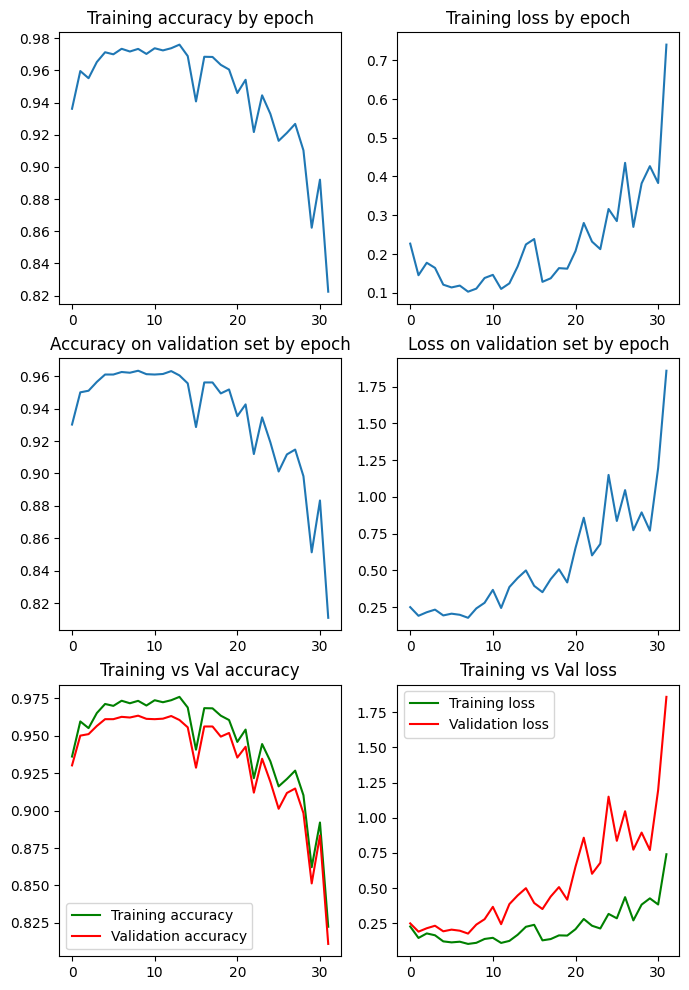

Restored validation checkpoint: epoch 8
Test score: 96.52%


In [21]:
model=MLP(X_train,y_train,dimensions=[128, 64 ,32, 10])
model.fit(X_train,y_train,X_val,y_val,lerning_rate=0.01,epoches=120,batch_size=32,beta=0.9, gamma=0.99, epsilon=1e-8, early_stop=True, early_stop_metric='loss',min_delta=1e-2,patience=24)
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Restored validation checkpoint: epoch {model.best_epoch_}")
print(f"Test score: {test_acc * 100:.2f}%")

## 6. Inspect predictions

Nine randomly selected test images show the true and predicted class. Green titles indicate a correct prediction;
red titles indicate a mistake. Change `seed` to view a different selection.

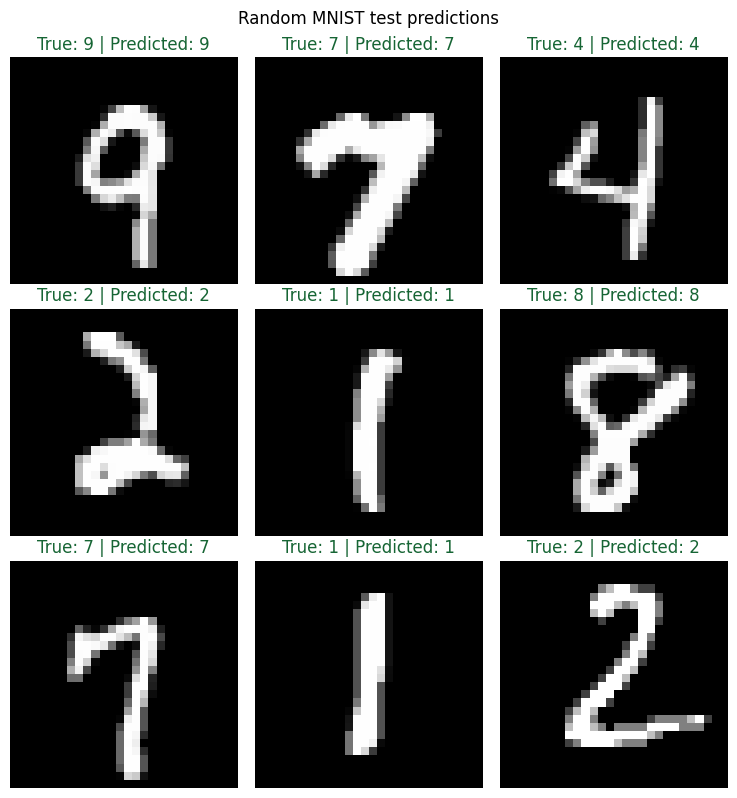

In [22]:
def show_random_predictions(model, images, labels, n=9, seed=SEED):
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(images), size=min(n, len(images)), replace=False)
    predictions = model.Predict(images[indices])
    true_classes = np.argmax(labels[indices], axis=1)

    columns = 3
    rows = int(np.ceil(len(indices) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(7.5, 2.7 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, idx, prediction, true_class in zip(axes.flat, indices, predictions, true_classes):
        ax.imshow(images[idx].reshape(28, 28), cmap="gray")
        color = "#166534" if prediction == true_class else "#b91c1c"
        ax.set_title(f"True: {true_class} | Predicted: {prediction}", color=color)
    fig.suptitle("Random MNIST test predictions")
    fig.tight_layout()
    plt.show()
    return indices

sample_indices = show_random_predictions(model, x_test, y_test)

### Follow one image through the model

The model receives a flattened image, computes the affine layer outputs with ReLU between layers,
and converts the final logits to softmax probabilities. The largest output determines the predicted class.
These probabilities are not calibrated confidence estimates.

Image: 28 x 28 -> flattened input: (1, 784)
Layer 1: (1, 128) -> ReLU
Layer 2: (1, 64) -> ReLU
Layer 3: (1, 32) -> ReLU
Layer 4: (1, 10) -> softmax
True class: 9; predicted class: 9


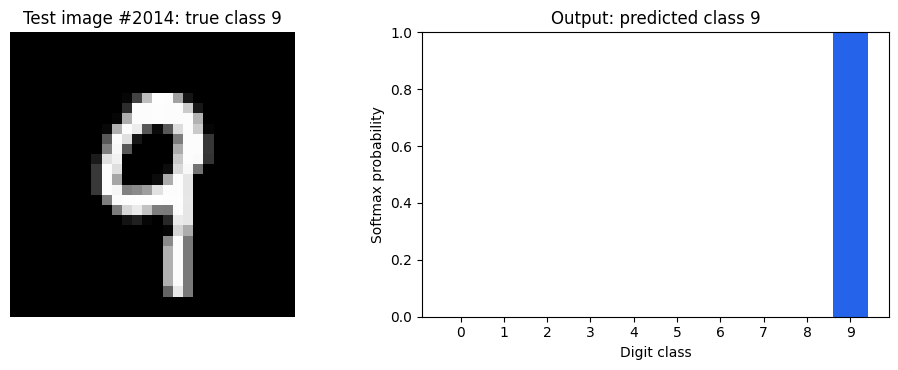

In [23]:
def show_prediction_steps(model, images, labels, index):
    image = images[index:index + 1]
    layer_outputs, _ = model.forward_pass(image)
    probabilities = model.softmax(layer_outputs[-1])[0]
    predicted_class = int(np.argmax(probabilities))
    true_class = int(np.argmax(labels[index]))

    print(f"Image: 28 x 28 -> flattened input: {image.shape}")
    for i, output in enumerate(layer_outputs, start=1):
        activation = " -> ReLU" if i < model.N else " -> softmax"
        print(f"Layer {i}: {output.shape}{activation}")
    print(f"True class: {true_class}; predicted class: {predicted_class}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    axes[0].imshow(image.reshape(28, 28), cmap="gray")
    axes[0].set_title(f"Test image #{index}: true class {true_class}")
    axes[0].axis("off")
    bar_colors = ["#2563eb" if i == predicted_class else "#cbd5e1" for i in range(10)]
    axes[1].bar(np.arange(10), probabilities, color=bar_colors)
    axes[1].set(xticks=np.arange(10), ylim=(0, 1), xlabel="Digit class", ylabel="Softmax probability")
    axes[1].set_title(f"Output: predicted class {predicted_class}")
    fig.tight_layout()
    plt.show()

show_prediction_steps(model, x_test, y_test, int(sample_indices[0]))